| **Inicio**         | **atrás 3**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./3_3_Estadistica.ipynb) |

# 1. El problema fundamental: inferir algo que no conocemos

Imagina que tenemos un sistema físico:

$$
\frac{du}{dt}=-ku
$$

donde:

* $(u(t))$ = estado del sistema
* $(k)$ = parámetro físico
* $(k)$ es desconocido

Tenemos mediciones:

$$
y_1,y_2,\ldots,y_n
$$

y queremos descubrir:

$$
\boxed{k=?}
$$

Esto es un **problema de inferencia**.

Tenemos:

```text
                  REALIDAD
                     │
                     ▼
             Sistema físico
                     │
                     ▼
             Datos observados
                     │
                     ▼
              ┌──────────────┐
              │   Inferencia │
              └──────────────┘
                     │
          ┌──────────┼──────────┐
          ▼          ▼          ▼
        MLE         MAP       Bayes
          │          │          │
          └──────────┴──────────┘
                     │
                     ▼
              parámetro k
```

# 2. Antes: probabilidad vs inferencia

Esta distinción es fundamental.

## Problema de probabilidad

Conocemos el modelo y queremos predecir datos.

Por ejemplo:

$$
k=0.5
$$

y sabemos que:

$$
y=f(x,k)+\epsilon
$$

Preguntamos:

> ¿Qué datos probablemente observaré?

Esto es:

$$
\boxed{\text{modelo}\rightarrow\text{datos}}
$$

## Problema de inferencia

Tenemos los datos y queremos descubrir el parámetro:

$$
y_1,\ldots,y_n
$$

y preguntamos:

> ¿Qué valor de $(k)$ probablemente produjo estos datos?

Esto es:

$$
\boxed{\text{datos}\rightarrow\text{parámetro}}
$$

Esta segunda dirección es la que nos interesa ahora.

# 3. Likelihood

Supongamos que nuestro modelo dice:

$$
Y_i=f(x_i,\theta)+\epsilon_i
$$

con:

$$
\epsilon_i\sim N(0,\sigma^2)
$$

Entonces:

$$
Y_i|\theta
\sim
N(f(x_i,\theta),\sigma^2)
$$

Tenemos datos:

$$
D=\{(x_i,y_i)\}_{i=1}^n
$$

La **likelihood** es:

$$
\boxed{
L(\theta|D)=p(D|\theta)
}
$$

si las observaciones son independientes:

$$
\boxed{
L(\theta|D)
=
\prod_{i=1}^{n}
p(y_i|\theta)
}
$$

# 4. Algo MUY importante sobre likelihood

La expresión:

$$
p(D|\theta)
$$

puede parecer una probabilidad de $(\theta)$.

**No lo es.**

Estamos preguntando:

> Si $(\theta)$ fuera este valor, ¿qué tan compatibles serían los datos observados con ese modelo?

Por ejemplo:

$$
L(0.2|D)=0.001
$$

$$
L(0.5|D)=0.15
$$

$$
L(0.8|D)=0.0001
$$

significa que los datos son mucho más compatibles con:

$$
\theta=0.5
$$

# 5. Ejemplo difícil de likelihood

Supongamos que estamos estudiando el decaimiento de una sustancia:

$$
C(t)=C_0e^{-kt}
$$

Sabemos:

$$
C_0=100
$$

pero desconocemos $(k)$.

Tenemos:

| $(t)$ | $(C)$ observado |
| ----: | --------------: |
|     0 |            99.1 |
|     1 |            73.4 |
|     2 |            54.2 |
|     3 |            40.1 |
|     4 |            30.1 |
|     5 |            22.0 |

Supongamos:

$$
\epsilon_i\sim N(0,\sigma^2)
$$

Entonces:

$$
C_i=100e^{-kt_i}+\epsilon_i
$$

# 6. Likelihood para este problema

Cada observación tiene:

$$
p(C_i|k)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp
\left[
-\frac{(C_i-100e^{-kt_i})^2}
{2\sigma^2}
\right]
$$

Como las observaciones son independientes:

$$
L(k)
=
\prod_i
p(C_i|k)
$$

Por cuestiones numéricas normalmente usamos el logaritmo:

$$
\boxed{
\ell(k)=\log L(k)
}
$$

y:

$$
\ell(k)
=
-\frac{n}{2}\log(2\pi\sigma^2)
-
\frac{1}{2\sigma^2}
\sum_i
(C_i-100e^{-kt_i})^2
$$

Observa algo extraordinario:

maximizar likelihood equivale a minimizar:

$$
\boxed{
\sum_i
(C_i-100e^{-kt_i})^2
}
$$

cuando $(\sigma)$ es constante.

Por eso aparece una conexión directa:

$$
\boxed{
\text{Maximum Likelihood}
\leftrightarrow
\text{Least Squares}
}
$$

bajo ruido gaussiano.

# 7. Python: visualizar la likelihood

MLE de k: 0.30375375375375374


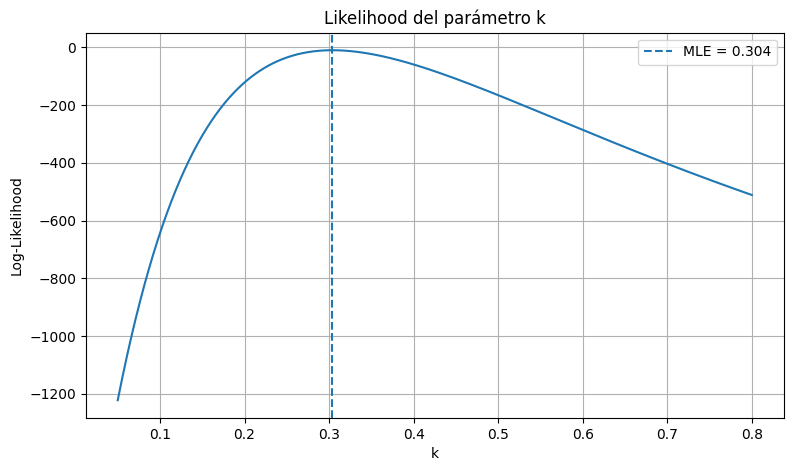

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.array([0, 1, 2, 3, 4, 5])

y = np.array([
    99.1,
    73.4,
    54.2,
    40.1,
    30.1,
    22.0
])

sigma = 2.0

k_values = np.linspace(0.05, 0.8, 1000)

log_likelihood = []

for k in k_values:

    prediction = 100 * np.exp(-k * t)

    residuals = y - prediction

    ll = (
        -len(y)/2 * np.log(2*np.pi*sigma**2)
        - np.sum(residuals**2)/(2*sigma**2)
    )

    log_likelihood.append(ll)

log_likelihood = np.array(log_likelihood)

k_mle = k_values[np.argmax(log_likelihood)]

print("MLE de k:", k_mle)

plt.figure(figsize=(9,5))

plt.plot(k_values, log_likelihood)

plt.axvline(
    k_mle,
    linestyle="--",
    label=f"MLE = {k_mle:.3f}"
)

plt.xlabel("k")
plt.ylabel("Log-Likelihood")
plt.title("Likelihood del parámetro k")
plt.legend()
plt.grid()

plt.show()

La gráfica tendrá un máximo.

Ese máximo es:

$$
\boxed{\hat{k}_{MLE}}
$$

# 8. Maximum Likelihood Estimation — MLE

Ahora formalizamos.

El estimador de máxima verosimilitud es:

$$
\boxed{
\hat{\theta}_{MLE}
=
\arg\max_\theta
L(\theta|D)
}
$$

Como el logaritmo es monótonamente creciente:

$$
\boxed{
\hat{\theta}_{MLE}
=
\arg\max_\theta
\log L(\theta|D)
}
$$

# 9. ¿Por qué usamos log-likelihood?

Porque:

$$
L(\theta)=\prod_i p(y_i|\theta)
$$

multiplicar miles de probabilidades pequeñas produce problemas numéricos.

Por ejemplo:

$$
0.01^{1000}
$$

es extremadamente pequeño.

En cambio:

$$
\log L
=
\sum_i\log p(y_i|\theta)
$$

es mucho más estable.

Por eso en Machine Learning se trabaja muchísimo con:

$$
\boxed{\log L}
$$

# 10. MLE en Machine Learning

Supongamos:

$$
y_i=f(x_i,\theta)+\epsilon_i
$$

con:

$$
\epsilon_i\sim N(0,\sigma^2)
$$

Entonces:

$$
\log L(\theta)
=
C
-
\frac{1}{2\sigma^2}
\sum_i
(y_i-f(x_i,\theta))^2
$$

Maximizar:

$$
\log L
$$

es equivalente a minimizar:

$$
\boxed{
\sum_i(y_i-f(x_i,\theta))^2
}
$$

Por tanto:

$$
\boxed{
\text{MSE / Least Squares}
\leftrightarrow
\text{Maximum Likelihood}
}
$$

cuando asumimos ruido gaussiano.

Esto explica parte de la fundamentación probabilística de muchos métodos de ML.

# 11. Prior

Ahora entra Bayesian inference.

Supongamos que antes de observar los datos tenemos algún conocimiento sobre $(\theta)$.

Por ejemplo:

$$
\theta>0
$$

y además creemos que probablemente:

$$
\theta\approx0.5
$$

Podemos representar ese conocimiento mediante:

$$
\boxed{
p(\theta)
}
$$

que se llama **prior**.

# 12. Ejemplo de prior

Supongamos:

$$
k\sim N(0.5,0.1^2)
$$

Esto significa:

$$
p(k)
=
\frac{1}{0.1\sqrt{2\pi}}
\exp
\left[
-\frac{(k-0.5)^2}{2(0.1)^2}
\right]
$$

Nuestro conocimiento previo dice:

> valores cercanos a $(0.5)$ son más plausibles.

Pero esto **no significa que sepamos que $(k=0.5)$**.

Es incertidumbre cuantificada.

# 13. Prior en la vida diaria

Imagina que estás estimando cuánto demora un bus.

Por experiencia sabes:

$$
T\approx30\text{ min}
$$

pero normalmente está entre 20 y 45 minutos.

Antes de observar el tráfico de hoy, tienes una distribución:

$$
p(T)
$$

Eso es conceptualmente un **prior**.

Luego observas:

* tráfico
* hora
* lluvia
* congestión
* GPS

y actualizas tu creencia.

# 14. Posterior

Aquí aparece la fórmula central de Bayesian inference:

$$
\boxed{
p(\theta|D)
=
\frac{
p(D|\theta)p(\theta)
}{
p(D)
}
}
$$

Es el **teorema de Bayes**.

Donde:

$$
\boxed{
p(\theta|D)
}
$$

es el posterior.

# 15. Las cuatro piezas fundamentales

Memoriza conceptualmente esto:

$$
\boxed{
\underbrace{p(\theta)}_{\text{Prior}}
\times
\underbrace{p(D|\theta)}_{\text{Likelihood}}
\propto
\underbrace{p(\theta|D)}_{\text{Posterior}}
}
$$

El denominador:

$$
p(D)
$$

es la evidencia o marginal likelihood:

$$
\boxed{
p(D)=\int p(D|\theta)p(\theta)d\theta
}
$$

para una variable continua.

# 16. Intuición visual

Piensa:

```text
PRIOR
¿Qué creía antes?
       │
       │
       ▼
LIKELIHOOD
¿Qué parámetros explican
bien los datos?
       │
       │
       ▼
POSTERIOR
¿Qué creo después de
ver los datos?
```

Matemáticamente:

$$
\boxed{
Posterior
\propto
Likelihood\times Prior
}
$$


# 17. Ejemplo completo: sensor médico

Supongamos que queremos saber si una persona tiene una enfermedad.

Definimos:

$$
D=\text{enfermedad}
$$

Nuestro conocimiento previo:

$$
P(D)=0.01
$$

Solo el 1% de la población tiene la enfermedad.

Ahora tenemos un test.

$$
P(+|D)=0.95
$$

El test detecta al 95% de los enfermos.

Pero también:

$$
P(+|D^c)=0.05
$$

El 5% de las personas sanas da falso positivo.

# 18. Likelihood

Si obtenemos:

$$
+
$$

entonces:

$$
P(+|D)=0.95
$$

y:

$$
P(+|D^c)=0.05
$$

Estos son elementos de la likelihood.

# 19. Posterior

Queremos:

$$
P(D|+)
$$

Bayes:

$$
P(D|+)
=
\frac{P(+|D)P(D)}
{P(+)}
$$

Calculamos:

$$
P(+)
=
P(+|D)P(D)
+
P(+|D^c)P(D^c)
$$

$$
=
0.95(0.01)+0.05(0.99)
$$

$$
=0.059
$$

Entonces:

$$
P(D|+)
=
\frac{0.0095}{0.059}
$$

$$
\boxed{
P(D|+)\approx0.161
}
$$

Es decir:

$$
\boxed{16.1\%}
$$

# 20. La sorpresa

Aunque el test dio positivo:

$$
P(D|+)\approx16.1\%
$$

no es:

$$
95\%
$$

¿Por qué?

Porque el **prior** era solamente:

$$
1\%
$$

Esto demuestra por qué el prior puede ser importante.

# 21. Python

In [2]:
import numpy as np
import matplotlib.pyplot as plt

prior = 0.01

likelihood_disease = 0.95
likelihood_no_disease = 0.05

evidence = (
    likelihood_disease * prior
    +
    likelihood_no_disease * (1 - prior)
)

posterior = (
    likelihood_disease * prior
    / evidence
)

print("Prior:", prior)
print("Likelihood P(+|D):", likelihood_disease)
print("Evidence:", evidence)
print("Posterior:", posterior)

Prior: 0.01
Likelihood P(+|D): 0.95
Evidence: 0.059000000000000004
Posterior: 0.16101694915254236


# 22. Bayesian inference

Bayesian inference no solamente produce un número.

Produce una **distribución completa sobre el parámetro**:

$$
\boxed{
p(\theta|D)
}
$$

Eso es una diferencia fundamental respecto de MLE.

MLE normalmente dice:

$$
\theta=0.48
$$

Bayesian inference puede decir:

$$
\theta|D
\sim
\text{alguna distribución}
$$

y podemos preguntar:

$$
P(0.4<\theta<0.6|D)
$$

o:

$$
E[\theta|D]
$$

o:

$$
Var(\theta|D)
$$

# 23. MLE vs Bayesian

Supongamos que queremos estimar:

$$
\theta
$$

### MLE

Busca:

$$
\boxed{
\hat{\theta}_{MLE}
=
\arg\max_\theta p(D|\theta)
}
$$

Solo utiliza likelihood.

### Bayesian

Calcula:

$$
\boxed{
p(\theta|D)
\propto
p(D|\theta)p(\theta)
}
$$

utiliza:

* datos
* conocimiento previo
* incertidumbre.

# 24. MAP

MAP significa:

$$
\boxed{\text{Maximum A Posteriori}}
$$

Busca el valor de $(\theta)$ que maximiza el posterior:

$$
\boxed{
\hat{\theta}_{MAP}
=
\arg\max_\theta
p(\theta|D)
}
$$

Como:

$$
p(\theta|D)
\propto
p(D|\theta)p(\theta)
$$

tenemos:

$$
\boxed{
\hat{\theta}_{MAP}
=
\arg\max_\theta
p(D|\theta)p(\theta)
}
$$

o usando logaritmos:

$$
\boxed{
\hat{\theta}_{MAP}
=
\arg\max_\theta
[
\log p(D|\theta)
+
\log p(\theta)
]
}
$$

# 25. Relación MLE → MAP

Esta relación es fundamental:

$$
\boxed{
MLE:
\max_\theta \log p(D|\theta)
}
$$

mientras:

$$
\boxed{
MAP:
\max_\theta
[
\log p(D|\theta)
+
\log p(\theta)
]
}
$$

Por tanto:

```text
MLE
│
└── solamente datos
       │
       ▼
    likelihood


MAP
│
├── datos
│
└── conocimiento previo
       │
       ▼
likelihood + prior
```

# 26. Ejemplo matemático muy importante

Supongamos:

$$
y_i=\theta+\epsilon_i
$$

donde:

$$
\epsilon_i\sim N(0,\sigma^2)
$$

y tenemos:

$$
\theta\sim N(\mu_0,\tau^2)
$$

Entonces:

$$
\boxed{
p(D|\theta)
\propto
\exp
\left[
-\frac{1}{2\sigma^2}
\sum_i(y_i-\theta)^2
\right]
}
$$

y:

$$
\boxed{
p(\theta)
\propto
\exp
\left[
-\frac{(\theta-\mu_0)^2}{2\tau^2}
\right]
}
$$

Por tanto:

$$
\log posterior
=
-\frac{1}{2\sigma^2}
\sum_i(y_i-\theta)^2
-
\frac{(\theta-\mu_0)^2}{2\tau^2}
+C
$$

Observa que el prior añade un término de penalización:

$$
\frac{(\theta-\mu_0)^2}{2\tau^2}
$$

# 27. MAP y regularización

Aquí aparece una conexión extremadamente importante con Machine Learning.

Supongamos:

$$
\theta\sim N(0,\tau^2)
$$

Entonces:

$$
\log p(\theta)
=
-\frac{\theta^2}{2\tau^2}+C
$$

Maximizar posterior equivale a minimizar:

$$
\boxed{
\text{error de datos}
+
\lambda\theta^2
}
$$

Esto es **regularización L2 / Ridge**.

Por tanto:

$$
\boxed{
MAP+\text{Gaussian prior}
\Longleftrightarrow
L_2\text{ regularization}
}
$$

Esta conexión debes aprenderla muy bien.

# 28. Y existe otra conexión

Si utilizamos un prior Laplaciano:

$$
p(\theta)\propto e^{-\lambda|\theta|}
$$

entonces:

$$
-\log p(\theta)
\propto
\lambda|\theta|
$$

y MAP produce:

$$
\boxed{
\text{error}+\lambda|\theta|
}
$$

que corresponde a:

$$
\boxed{L_1\text{ regularization / Lasso}}
$$

Así:

$$
\boxed{
Gaussian\ prior\rightarrow L_2
}
$$

$$
\boxed{
Laplace\ prior\rightarrow L_1
}
$$

Esta es una de las conexiones más bonitas entre probabilidad y Machine Learning.

# 29. Ejemplo visual: MLE vs MAP

Supongamos que la likelihood tiene su máximo en:

$$
\theta=0.8
$$

pero nuestro prior favorece:

$$
\theta=0.5
$$

Entonces:

```text
Likelihood:

                  /\
                 /  \
                /    \
_______________/      \________
             0.8


Prior:

             /\
            /  \
           /    \
__________/      \______________
        0.5
```

Al multiplicarlas:

$$
Posterior
\propto
Likelihood\times Prior
$$

el máximo puede desplazarse:

$$
0.8
\rightarrow
0.65
$$

Ese nuevo máximo es:

$$
\boxed{\theta_{MAP}}
$$

# 30. Python: MLE vs MAP

MLE: 0.7997997997997998
MAP: 0.6826826826826827


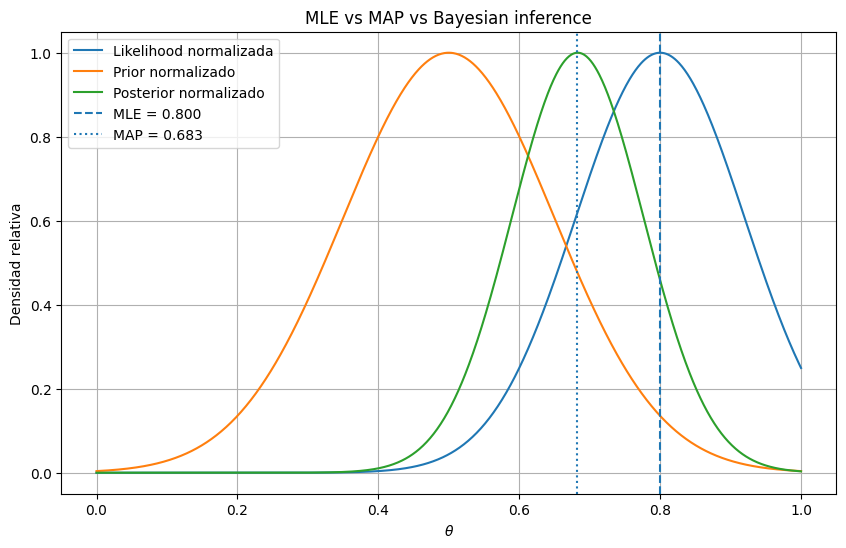

In [3]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 1, 1000)

# Likelihood
likelihood = np.exp(
    -(theta - 0.8)**2 / (2 * 0.12**2)
)

# Prior
prior = np.exp(
    -(theta - 0.5)**2 / (2 * 0.15**2)
)

# Posterior proporcional
posterior = likelihood * prior

# Normalizamos para visualizar
posterior /= np.trapezoid(
    posterior,
    theta
)

theta_mle = theta[np.argmax(likelihood)]
theta_map = theta[np.argmax(posterior)]

print("MLE:", theta_mle)
print("MAP:", theta_map)

plt.figure(figsize=(10, 6))

plt.plot(
    theta,
    likelihood / np.max(likelihood),
    label="Likelihood normalizada"
)

plt.plot(
    theta,
    prior / np.max(prior),
    label="Prior normalizado"
)

plt.plot(
    theta,
    posterior / np.max(posterior),
    label="Posterior normalizado"
)

plt.axvline(
    theta_mle,
    linestyle="--",
    label=f"MLE = {theta_mle:.3f}"
)

plt.axvline(
    theta_map,
    linestyle=":",
    label=f"MAP = {theta_map:.3f}"
)

plt.xlabel(r"$\theta$")
plt.ylabel("Densidad relativa")
plt.title("MLE vs MAP vs Bayesian inference")
plt.legend()
plt.grid()

plt.show()

# 31. Bayesian inference produce más que MAP

Aquí debes tener mucho cuidado.

MAP:

$$
\boxed{
\theta_{MAP}
}
$$

es solamente **un punto**.

Bayesian inference produce:

$$
\boxed{
p(\theta|D)
}
$$

la distribución posterior completa.

Por ejemplo:

$$
\theta|D
\sim N(0.63,0.04^2)
$$

Entonces podemos calcular:

### Media posterior

$$
E[\theta|D]
$$


### Varianza posterior

$$
Var(\theta|D)
$$

### Intervalo creíble

Por ejemplo:

$$
P(0.55<\theta<0.71|D)=0.95
$$

# 32. Intervalo creíble vs intervalo de confianza

Esto será importante.

### Frequentista

Intervalo de confianza:

$$
CI_{95\%}
$$

se interpreta mediante el procedimiento de muestreo.

### Bayesian

Intervalo creíble:

$$
\boxed{
P(\theta\in[a,b]|D)=0.95
}
$$

sí permite decir:

> Dado nuestro modelo y nuestros datos, existe un 95% de probabilidad posterior de que $(\theta)$ esté dentro de este intervalo.

La interpretación es diferente.

# 33. Ejemplo SciML completo

Ahora vamos a juntar TODO.

Tenemos:

$$
\frac{du}{dt}=-ku
$$

con:

$$
u(0)=100
$$

Solución:

$$
u(t)=100e^{-kt}
$$

Tenemos datos experimentales:

$$
D=\{t_i,y_i\}
$$

con ruido:

$$
y_i=100e^{-kt_i}+\epsilon_i
$$

$$
\epsilon_i\sim N(0,\sigma^2)
$$

## Paso 1 — Prior

Antes de observar los datos:

$$
k\sim N(0.3,0.1^2)
$$

## Paso 2 — Likelihood

$$
p(D|k)
=
\prod_i
N(y_i|100e^{-kt_i},\sigma^2)
$$

## Paso 3 — Posterior

$$
\boxed{
p(k|D)
\propto
p(D|k)p(k)
}
$$

## Paso 4 — MLE

$$
\boxed{
k_{MLE}
=
\arg\max_k p(D|k)
}
$$

## Paso 5 — MAP

$$
\boxed{
k_{MAP}
=
\arg\max_k p(k|D)
}
$$

## Paso 6 — Bayesian inference

En lugar de solamente guardar:

$$
k_{MAP}
$$

guardamos:

$$
\boxed{
p(k|D)
}
$$

y podemos obtener:

$$
E[k|D]
$$

$$
Var(k|D)
$$

$$
CI_{\text{creíble}}
$$

y predicciones:

$$
p(u(t_{future})|D)
$$

# 34. Implementación completa en Python

k verdadero: 0.35
k MLE: 0.34902451225612807
k MAP: 0.3486493246623312
Media posterior: 0.34888364792396737


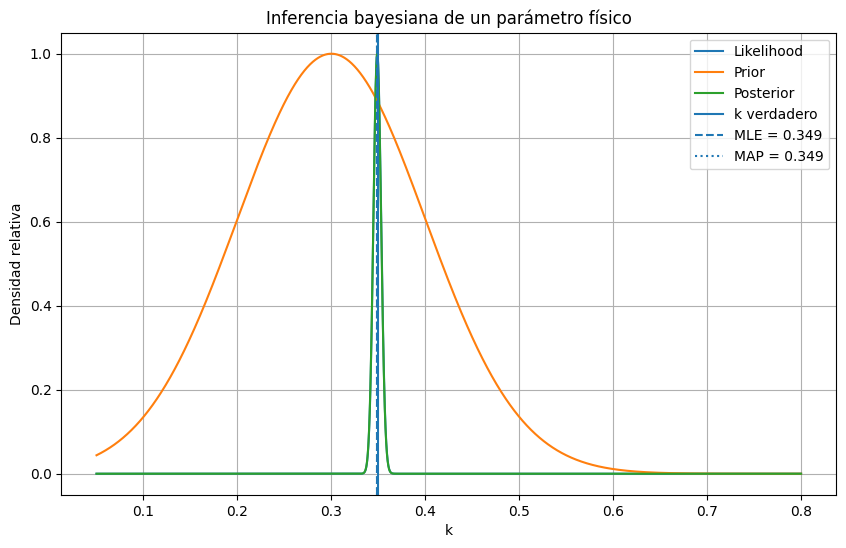

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# --------------------------------
# Datos experimentales
# --------------------------------

rng = np.random.default_rng(42)

t = np.linspace(0, 5, 30)

k_true = 0.35
sigma = 2.0

y_true = 100 * np.exp(-k_true * t)

y = y_true + rng.normal(
    0,
    sigma,
    size=len(t)
)

# --------------------------------
# Espacio de parámetros
# --------------------------------

k_values = np.linspace(
    0.05,
    0.8,
    2000
)

# --------------------------------
# Prior
# --------------------------------

prior = norm.pdf(
    k_values,
    loc=0.30,
    scale=0.10
)

# --------------------------------
# Likelihood
# --------------------------------

log_likelihood = np.zeros_like(k_values)

for i, k in enumerate(k_values):

    prediction = 100 * np.exp(-k * t)

    residuals = y - prediction

    log_likelihood[i] = (
        -len(y) / 2 * np.log(
            2 * np.pi * sigma**2
        )
        -
        np.sum(residuals**2)
        / (2 * sigma**2)
    )

# Evitamos problemas numéricos
likelihood = np.exp(
    log_likelihood -
    np.max(log_likelihood)
)

# --------------------------------
# Posterior
# --------------------------------

posterior = likelihood * prior

posterior /= np.trapezoid(
    posterior,
    k_values
)

# --------------------------------
# MLE y MAP
# --------------------------------

k_mle = k_values[
    np.argmax(likelihood)
]

k_map = k_values[
    np.argmax(posterior)
]

# Media posterior
posterior_mean = np.trapezoid(
    k_values * posterior,
    k_values
)

print("k verdadero:", k_true)
print("k MLE:", k_mle)
print("k MAP:", k_map)
print("Media posterior:", posterior_mean)

# --------------------------------
# Gráfica
# --------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    likelihood / np.max(likelihood),
    label="Likelihood"
)

plt.plot(
    k_values,
    prior / np.max(prior),
    label="Prior"
)

plt.plot(
    k_values,
    posterior / np.max(posterior),
    label="Posterior"
)

plt.axvline(
    k_true,
    linestyle="-",
    label="k verdadero"
)

plt.axvline(
    k_mle,
    linestyle="--",
    label=f"MLE = {k_mle:.3f}"
)

plt.axvline(
    k_map,
    linestyle=":",
    label=f"MAP = {k_map:.3f}"
)

plt.xlabel("k")
plt.ylabel("Densidad relativa")
plt.title(
    "Inferencia bayesiana de un parámetro físico"
)

plt.legend()
plt.grid()

plt.show()

# 35. ¿Qué acabamos de hacer?

Hicimos algo que aparece constantemente en SciML:

$$
\boxed{
\text{Modelo físico}
+
\text{datos experimentales}
+
\text{modelo probabilístico}
}
$$

produjo:

$$
\boxed{
p(k|D)
}
$$

Es decir:

> una distribución de incertidumbre sobre el parámetro físico.

Esto es mucho más potente que simplemente obtener:

$$
k=0.347
$$

# 36. MLE, MAP y Bayes: comparación definitiva


| Concepto           | Utiliza datos | Utiliza prior | Resultado                      |
| ------------------ | ------------: | ------------: | ------------------------------ |
| Likelihood         |             ✅ |             ❌ | compatibilidad datos/parámetro |
| MLE                |             ✅ |             ❌ | un valor                       |
| Prior              |             ❌ |             ✅ | creencia previa                |
| Posterior          |             ✅ |             ✅ | distribución                   |
| MAP                |             ✅ |             ✅ | un valor                       |
| Bayesian inference |             ✅ |             ✅ | distribución completa          |

Matemáticamente:

### Likelihood

$$
\boxed{p(D|\theta)}
$$

### Prior

$$
\boxed{p(\theta)}
$$

### Posterior

$$
\boxed{
p(\theta|D)
\propto
p(D|\theta)p(\theta)
}
$$

### MLE

$$
\boxed{
\hat\theta_{MLE}
=
\arg\max_\theta p(D|\theta)
}
$$

### MAP

$$
\boxed{
\hat\theta_{MAP}
=
\arg\max_\theta
p(\theta|D)
}
$$

# 37. La conexión con Machine Learning

Esta parte debes guardarla.

```text
                    PROBABILIDAD
                         │
                         ▼
                   Distribuciones
                         │
                         ▼
                    Likelihood
                         │
             ┌───────────┴───────────┐
             ▼                       ▼
            MLE                     Bayes
             │                       │
             │                       ▼
             │                     Prior
             │                       │
             │                       ▼
             │                    Posterior
             │                       │
             │                       ▼
             │                      MAP
             │
             ▼
      Optimización
             │
             ▼
       Machine Learning
```

Y:

$$
\boxed{
MAP
\leftrightarrow
Regularización
}
$$

Por ejemplo:

$$
Gaussian\ prior
\leftrightarrow
L_2
$$

$$
Laplace\ prior
\leftrightarrow
L_1
$$

# 38. La conexión con SciML

Para SciML la cadena se vuelve:

$$
\boxed{
\text{Modelo físico}
\rightarrow
\text{Likelihood}
\rightarrow
\text{Inferencia}
\rightarrow
\text{Parámetros}
\rightarrow
\text{Predicción}
}
$$

Por ejemplo:

$$
\frac{\partial u}{\partial t}
=
\alpha
\frac{\partial^2u}{\partial x^2}
$$

donde:

$$
\alpha
$$

es una difusividad desconocida.

Tenemos mediciones:

$$
u(x_i,t_i)
$$

Queremos inferir:

$$
\boxed{\alpha}
$$

Podemos hacer:

$$
p(\alpha|D)
\propto
p(D|\alpha)p(\alpha)
$$

y ahora no solamente conocemos una estimación de $(\alpha)$, sino su incertidumbre.

Eso es la base de problemas como:

* **parameter estimation**
* **inverse problems**
* **uncertainty quantification**
* **Bayesian calibration**
* **Bayesian neural networks**
* **Gaussian processes**
* **physics-informed inference**
* **data assimilation**
* **scientific model calibration**

# 39. Algo todavía más importante: el problema inverso

Observa la diferencia:

### Problema directo

Conocemos:

$$
\alpha
$$

y resolvemos:

$$
u_t=\alpha u_{xx}
$$

para obtener:

$$
u(x,t)
$$

Entonces:

$$
\boxed{
\alpha\rightarrow u
}
$$

### Problema inverso

Tenemos:

$$
u(x,t)
$$

medido experimentalmente y queremos descubrir:

$$
\alpha
$$

Entonces:

$$
\boxed{
u\rightarrow\alpha
}
$$

La inferencia bayesiana proporciona:

$$
\boxed{
p(\alpha|u)
}
$$

en lugar de solamente:

$$
\alpha=?
$$

Y esto es central en SciML.

| **Inicio**         | **atrás 3**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./3_3_Estadistica.ipynb) |